# Drought index per department and month

**Goal:** the drought data (SPEI1, SPI1) is a grid of squares. We need one value per department and month, in one CSV file.

**Method:** an area-weighted mean. Every grid square counts by the share of the department that lies inside it. This also works for departments that are smaller than one square, like Mfoundi.

The notebook has two parts.

**Part 1: how it works, step by step** (with SPEI1)

| Step | What happens | Result |
|---|---|---|
| Load | open the grid files and the department boundaries | `spei`, `gdf58` |
| A | make one square around every grid point | `cells` (1,750 squares) |
| B | cut the squares along the department borders | `pieces` (1,151 pieces) |
| C | measure every piece and turn the areas into weights | columns `area_km2`, `weight` |
| D | multiply values by weights and add up per department and month | `result` (20,880 rows) |
| Missing values | what goes wrong when squares have no value, and the fix | shown with SPI1 |

**Part 2: the final pipeline**

The same steps, packed into the functions of `grid_to_departments.py`. They are run for SPEI1 and SPI1, the two tables are merged, checked and saved as a CSV file.

**Still open:** the EDDI data is not there yet. When it is, it needs one more call of the function and one more merge.

# Part 1: how it works, step by step

In [1]:
import xarray as xr                # reads the grid files (NetCDF)
import geopandas as gpd            # tables with shapes (departments, squares)
from shapely.geometry import box   # makes a rectangle from its four edges

## File paths

**Change these before you run the notebook.** All files are read and written through these three paths, so this is the only cell you need to edit.

The paths are relative to this notebook, which is in the folder `drought/` of the repo. `..` means one folder up.

| Path | What it is | In the repo? |
|---|---|---|
| `GRID_DIR` | the folder with the monthly grid files (`SPEI1_*.nc`, `SPI1_*.nc`) | no, everyone keeps them on their own computer |
| `BOUNDARIES_FILE` | the cleaned department borders | yes, the same for everyone |
| `OUTPUT_DIR` | the folder where the final CSV is saved | no, it must be outside the repo |

In [2]:
# folder with the grid files; change this to where they are on your computer
GRID_DIR = "../../../data/raw"

# the shared boundaries file in this repo; no need to change it
BOUNDARIES_FILE = "../data/boundaries/cmr_adm2_58.geojson"

# folder for the final CSV; outside the repo, because the repo ignores CSV files
OUTPUT_DIR = "../../../data/processed"

## Load the data

**The grid:** there is one file per month, 360 files from 1996-01 to 2025-12. `open_mfdataset` opens them all and stacks them along `time`.

The result has three dimensions:

| Dimension | Length | Meaning |
|---|---|---|
| `time` | 360 | the month |
| `lat` | 50 | latitude, from 13.5 (north) down to 1.25 (south) |
| `lon` | 35 | longitude, from 8.0 (west) up to 16.5 (east) |

The drought values are in the data variable `SPEI1`.

In [3]:
# open all SPEI1 files and stack them along the time axis
spei = xr.open_mfdataset(f"{GRID_DIR}/SPEI1_*.nc", combine="nested", concat_dim="time")
spei

<xarray.Dataset> Size: 5MB
Dimensions:  (time: 360, lat: 50, lon: 35)
Coordinates:
  * time     (time) datetime64[ns] 3kB 1996-01-01T06:00:00 ... 2025-12-01T06:...
  * lat      (lat) float64 400B 13.5 13.25 13.0 12.75 12.5 ... 2.0 1.75 1.5 1.25
  * lon      (lon) float64 280B 8.0 8.25 8.5 8.75 9.0 ... 15.75 16.0 16.25 16.5
Data variables:
    SPEI1    (time, lat, lon) float64 5MB dask.array<chunksize=(1, 50, 35), meta=np.ndarray>
Attributes: (12/19)
    title:                   SPEI1
    description:             Drought Index: Standardized Drought Index calcul...
    Conventions:             CF-1.8
    history:                 Created 25/10/2024 23:13:36 using DRYFALL.
    institution:             European Centre for Medium-Range Weather Forecasts
    source:                  DRYFALL v1.0
    ...                      ...
    frequency:               Monthly
    contact_person:          support@ecmwf.int
    ref_publication:         Keune, J., Di Giuseppe, F., Barnard, C., Damasio...
    cds_data_catalogue_url:  https://cds.climate.copernicus.eu/datasets/deriv...
    product_type:            Reanalysis
    dataset_type:            Consolidated dataset

**The boundaries:** the cleaned geoBoundaries file from the repo (`BOUNDARIES_FILE`). It has one row per department, with the columns `shapeName` and `geometry`.

In [4]:
gdf58 = gpd.read_file(BOUNDARIES_FILE)
print(len(gdf58))  # expected: 58 departments

58


## Step A: one square per grid point

Each grid point is the **centre** of a square. The points are 0.25 degrees apart, so every square reaches half of that, 0.125 degrees, in each direction.

Example for the point at latitude 4.0, longitude 11.5:

| Edge | Calculation | Result |
|---|---|---|
| west | 11.5 - 0.125 | 11.375 |
| east | 11.5 + 0.125 | 11.625 |
| south | 4.0 - 0.125 | 3.875 |
| north | 4.0 + 0.125 | 4.125 |

The function goes through every latitude and every longitude and builds one square for each pair.

In [5]:
def to_square(ds, half):
    # ds   - the grid dataset, with the coordinates "lat" and "lon"
    # half - half the side of one square, in degrees (0.125 for a 0.25 degree grid)

    # three lists that grow together: position i in each list belongs to square i
    latitudes = []
    longitudes = []
    boxes = []

    # every latitude combined with every longitude is one grid point
    for lat in ds["lat"].values:
        for lon in ds["lon"].values:
            latitudes.append(lat)
            longitudes.append(lon)
            # box takes the edges in this order: west, south, east, north
            boxes.append(box(lon-half, lat-half, lon+half, lat+half))

    # put the three lists into one table
    # gpd - geopandas
    # EPSG:4326 - longitude and latitude in degrees, the same system as the boundaries
    return gpd.GeoDataFrame({"lat":latitudes, "lon": longitudes}, geometry=boxes, crs="EPSG:4326")

In [6]:
cells = to_square(spei, 0.125)
print(len(cells))  # expected: 50 * 35 = 1750 squares

1750


**Check:** draw both layers in one picture. Cameroon (red) must lie inside the grid (grey), with a small margin around it.

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

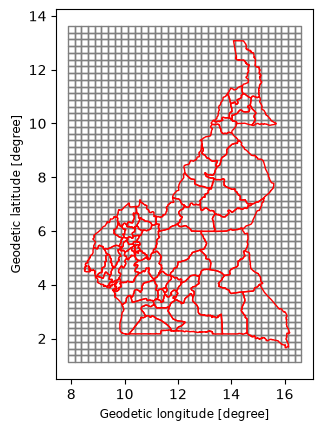

In [7]:
ax = cells.plot(facecolor="none", edgecolor="grey")   # the grid, saved as drawing area "ax"
gdf58.plot(ax=ax,facecolor="none", edgecolor="red")   # the departments, drawn on the same area

## Step B: cut the squares with the departments

`overlay` works like scissors. It does three things at once:

1. Squares outside Cameroon are removed.
2. Squares that cross a border are cut into pieces, one piece per department.
3. Every piece gets the name of its department.

Each row of `pieces` is the part of **one square** that lies inside **one department**. It keeps the `lat` and `lon` of its square.

In [8]:
pieces = gpd.overlay(cells, gdf58, how="intersection")
print(len(pieces))  # expected: 1151 pieces

1151


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

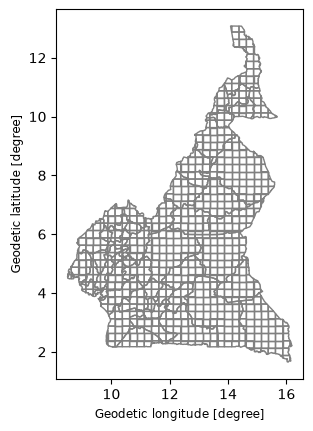

In [9]:
pieces.plot(facecolor="none",edgecolor="grey")

## Step C: from areas to weights

A big piece must count more than a small one, so we need the area of every piece.

**Why `to_crs`:** the shapes are stored in degrees, and degrees are angles, not lengths. For measuring, the shapes are converted to EPSG:6933, a map system in metres that keeps areas correct. The table `pieces` itself stays in degrees.

**The weight** is the share of the department that lies in this square:

weight = area of the piece / total area of all pieces of the same department

The weights of one department add up to 1.

In [10]:
# area of every piece: square metres, divided by one million to get square kilometres
pieces["area_km2"] = pieces.to_crs("EPSG:6933").area /1e6

# total area of the department, written into every row of that department
total = pieces.groupby("shapeName")["area_km2"].transform("sum")

# share of the department that lies in this piece
pieces["weight"] = pieces["area_km2"] / total

**Check 1:** Mfoundi touches only two squares. Almost all of it (about 256 of 263 square km) lies in the lower one, so the weights are about 0.03 and 0.97.

In [11]:
pieces[pieces["shapeName"] == "Mfoundi"]

,lat,lon,shapeName,geometry,area_km2,weight
842,4.00,11.5,Mfoundi,"POLYGON ((11.48545 3.875, 11.49679 3.87748, 11...",7.096400,0.026952
886,3.75,11.5,Mfoundi,"POLYGON ((11.56621 3.875, 11.5858 3.85689, 11....",256.199318,0.973048


**Check 2:** the weights of every department must add up to 1. The smallest and the largest sum are printed, and both should be 1.0.

In [12]:
sums = pieces.groupby("shapeName")["weight"].sum()   # one sum per department
print(sums.min(), sums.max())

0.9999999999999999 1.0000000000000002


## Step D: the weighted mean

Now the two sides meet:

- `pieces` knows for every square the **department** and the **weight**.
- the grid knows for every square and month the **drought value**.

Both identify a square by `lat` and `lon`, so the two tables are joined on these columns.

First the grid is turned into a normal table, with one row for every square in every month.

In [13]:
values = spei["SPEI1"].to_dataframe().reset_index()   # columns: time, lat, lon, SPEI1
print(len(values))  # expected: 360 * 50 * 35 = 630000 rows

630000


`merge` attaches the drought values to the pieces. Every piece gets the value of its square, once for each month.

In [14]:
joined = pieces.merge(values, on=["lat","lon"])
print(len(joined))  # expected: 1151 pieces * 360 months = 414360 rows

414360


The mean of a department in one month is: value times weight for each piece, then the sum of these.

Adding is enough, and no division is needed, because the weights already add up to 1.

Example, Mfoundi in July 2020: 0.03 x (-0.26) + 0.97 x (-0.37) = about -0.37

In [15]:
# value of the square times the weight of the piece
joined["weighted"] = joined["SPEI1"] * joined["weight"]

# one group per department and month, add up the weighted values
result = joined.groupby(["shapeName", "time"])["weighted"].sum().reset_index()

# the sum is the mean SPEI1 of the department, so the column gets that name
result = result.rename(columns={"weighted": "SPEI1"})

print(len(result))  # expected: 58 departments * 360 months = 20880 rows
result.head()

20880


,shapeName,time,SPEI1
0,Bamboutos,1996-01-01 06:00:00,-0.763288
1,Bamboutos,1996-02-01 06:00:00,0.156837
2,Bamboutos,1996-03-01 06:00:00,1.356246
3,Bamboutos,1996-04-01 06:00:00,0.685341
4,Bamboutos,1996-05-01 06:00:00,0.154120


**Check:** Mfoundi in July 2020 should be about -0.37, the value worked out by hand above.

The time needs the full stamp, because the files mark every month as the 1st at 06:00.

In [16]:
result[(result["shapeName"] == "Mfoundi") & (result["time"] == "2020-07-01 06:00")]

,shapeName,time,SPEI1
14694,Mfoundi,2020-07-01 06:00:00,-0.369552


## Missing values

SPEI1 has no gaps inside Cameroon, so step D is correct for it. SPI1 is different.

SPI is computed from rainfall. In the dry season, the north of Cameroon has months with no rain at all. The index cannot be calculated then, and the squares hold no value (`NaN`).

First the SPI1 files are opened, and the number of empty squares is counted for every month.

In [17]:
spi = xr.open_mfdataset(f"{GRID_DIR}/SPI1_*.nc", combine="nested", concat_dim="time")

# number of empty squares in every month
empty = spi["SPI1"].isnull().sum(["lat", "lon"]).values
print(empty.min(), empty.max())  # 76 squares over the ocean are always empty; the rest changes by month

76 709


Now step D is repeated for SPI1, in the same way as for SPEI1. The weights in `pieces` can be used again, because both indexes are on the same grid.

In [18]:
values_spi = spi["SPI1"].to_dataframe().reset_index()
joined_spi = pieces.merge(values_spi, on=["lat","lon"])
joined_spi["weighted"] = joined_spi["SPI1"] * joined_spi["weight"]

# the simple version from step D
simple_spi = joined_spi.groupby(["shapeName", "time"])["weighted"].sum().reset_index()

**The problem:** `sum()` skips empty squares without a warning. Two things go wrong:

| Case | What happens | Why it is wrong |
|---|---|---|
| Some squares of a department are empty | the weights that are left do not add up to 1 | the mean is pulled towards 0 |
| All squares are empty | the sum of nothing is 0 | 0 means "a normal month", but the truth is "no data" |

The second case is easy to see: results that are exactly 0.

In [19]:
simple_spi[simple_spi["weighted"] == 0]

,shapeName,time,weighted
637,Benoue,2019-02-01 06:00:00,0.0
2077,Diamare,2019-02-01 06:00:00,0.0
3755,Faro,2008-12-01 06:00:00,0.0
9277,Mayo-Danay,2019-02-01 06:00:00,0.0
9637,Mayo-Kani,2019-02-01 06:00:00,0.0
9997,Mayo-Louti,2019-02-01 06:00:00,0.0
10717,Mayo-Sava,2019-02-01 06:00:00,0.0
11077,Mayo-Tsanaga,2019-02-01 06:00:00,0.0


**The fix:** divide by the weights that were really used.

`valid_weight` is the weight where the square has a value, and 0 where it is empty. Both columns are added up per department and month, and then divided.

If a department has no data at all, this is 0 divided by 0, which gives `NaN`. That is the honest answer.

In [20]:
# the weight counts only where the square has a value, otherwise 0
joined_spi["valid_weight"] = joined_spi["weight"].where(joined_spi["SPI1"].notna(), 0)

# add up both columns per department and month
sums_spi = joined_spi.groupby(["shapeName", "time"])[["weighted", "valid_weight"]].sum().reset_index()

# divide by the weights that were really used
sums_spi["SPI1"] = sums_spi["weighted"] / sums_spi["valid_weight"]

**Check:** no result is exactly 0 any more, and the 8 cases without data are now marked as missing.

In [21]:
print(len(sums_spi[sums_spi["SPI1"] == 0]))   # expected: 0 fake zeros
print(sums_spi["SPI1"].isna().sum())           # expected: 8 results with no data

0
8


`valid_weight` also shows how much of a department had data in a month: 1 means all of it, 0.5 means half.

The table below counts the results that are based on less than half of the department. They are kept for now. Whether such results should be set to missing is an open decision.

In [22]:
low = sums_spi[sums_spi["valid_weight"] < 0.5]
print(len(low))                             # results based on less than half of the department
low["shapeName"].value_counts()             # which departments, and how often

66


shapeName
Logone-Et-Chari    11
Mayo-Sava          11
Faro                8
Faro-et-Deo         8
Mayo-Rey            6
Mayo-Tsanaga        5
Vina                4
Benoue              3
Diamare             3
Mayo-Danay          3
Mayo-Kani           3
Mayo-Louti          1
Name: count, dtype: int64

# Part 2: the final pipeline

All steps from part 1 are packed into two functions in the file `grid_to_departments.py`:

| Function | Steps | Returns |
|---|---|---|
| `make_weights(ds, departments)` | A, B, C | the pieces with their weights |
| `department_means(ds, var, weights)` | D, with the fix for missing values | one row per department and month |

The weights depend only on the grid and the borders. They are computed once and used for both indexes.

In [23]:
from grid_to_departments import make_weights, department_means

weights = make_weights(spei, gdf58)                      # once per grid
table_spei = department_means(spei, "SPEI1", weights)    # once per index
table_spi = department_means(spi, "SPI1", weights)

print(len(table_spei), len(table_spi))  # expected: 20880 each

20880 20880


**Check:** the functions must give the same numbers as the step-by-step version in part 1.

In [24]:
# largest difference between the two versions, should be 0
print((table_spei["SPEI1"] - result["SPEI1"]).abs().max())
print((table_spi["SPI1"] - sums_spi["SPI1"]).abs().max())

8.881784197001252e-16
0.0


## Merge the tables

Both tables have the columns `shapeName` and `time`. `merge` puts the rows with the same department and month next to each other.

`how="outer"` keeps a row even if one of the two tables has no entry for it, so nothing is lost without notice.

In [25]:
merged = table_spei.merge(table_spi, on=["shapeName", "time"], how="outer")

# the files stamp every month as the 1st at 06:00; keep only the date
merged["time"] = merged["time"].dt.normalize()

# sort by department, then by month
merged = merged.sort_values(["shapeName", "time"]).reset_index(drop=True)

print(len(merged))  # expected: 20880
merged.head()

20880


,shapeName,time,SPEI1,SPI1
0,Bamboutos,1996-01-01,-0.763288,-0.570748
1,Bamboutos,1996-02-01,0.156837,0.719904
2,Bamboutos,1996-03-01,1.356246,1.366806
3,Bamboutos,1996-04-01,0.685341,0.594500
4,Bamboutos,1996-05-01,0.154120,0.096685


## Checks

**1. Number of departments:** 58.

In [26]:
print(merged["shapeName"].nunique())  # expected: 58

58


**2. No missing months:** every department must have all 360 months from 1996-01 to 2025-12, and each one only once.

In [27]:
import pandas as pd

# the 360 months that must be there
expected = pd.date_range("1996-01-01", "2025-12-01", freq="MS")

# number of rows per department: smallest and largest, both must be 360
per_department = merged.groupby("shapeName")["time"].count()
print(per_department.min(), per_department.max())

# the months in the table are exactly the expected ones
print(set(merged["time"]) == set(expected))                     # expected: True

# no department and month appears twice
print(merged.duplicated(["shapeName", "time"]).sum())           # expected: 0

360 360
True
0


**3. Missing values:** SPEI1 should have none. SPI1 has 8, the department-months in the north without any data.

In [28]:
print(merged[["SPEI1", "SPI1"]].isna().sum())
merged[merged["SPI1"].isna()]

SPEI1    0
SPI1     8
dtype: int64


,shapeName,time,SPEI1,SPI1
637,Benoue,2019-02-01,1.212179,NaN
2077,Diamare,2019-02-01,1.012587,NaN
3755,Faro,2008-12-01,0.977297,NaN
9277,Mayo-Danay,2019-02-01,1.029195,NaN
9637,Mayo-Kani,2019-02-01,1.294774,NaN
9997,Mayo-Louti,2019-02-01,1.586883,NaN
10717,Mayo-Sava,2019-02-01,0.945598,NaN
11077,Mayo-Tsanaga,2019-02-01,1.334831,NaN


**4. Range of the values:** a drought index is normally between about -3 and 3. Some squares in the files hold much larger values, down to -8.2. A few department means are therefore outside the normal range. They are kept as they are in the files.

In [29]:
merged[["SPEI1", "SPI1"]].describe()

,SPEI1,SPI1
count,20880.000000,20872.000000
mean,-0.177518,-0.089802
std,1.003728,1.156078
min,-6.936837,-8.222082
25%,-0.860509,-0.688759
50%,-0.203460,-0.060312
75%,0.493428,0.588853
max,4.942702,6.434798


**5. One department over time:** Mfoundi, both indexes. Values below 0 are drier than normal, values above 0 are wetter.

Text(0, 0.5, 'index value')

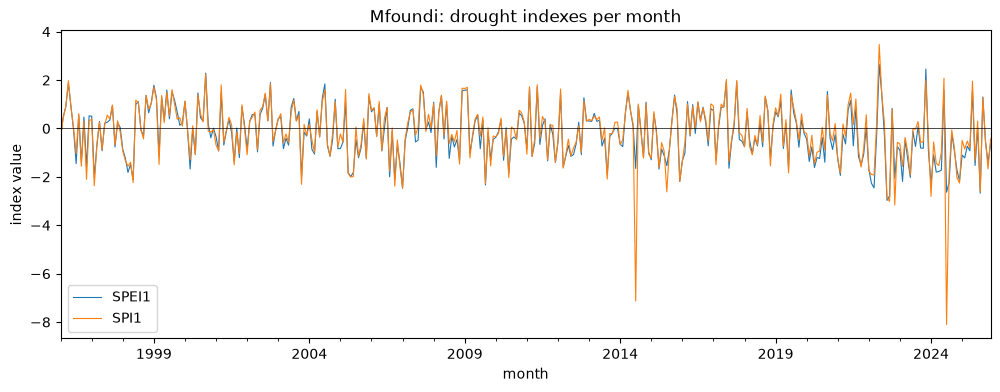

In [30]:
one = merged[merged["shapeName"] == "Mfoundi"]

ax = one.plot(x="time", y=["SPEI1", "SPI1"], figsize=(12, 4), linewidth=0.8)
ax.axhline(0, color="black", linewidth=0.5)   # the line for a normal month
ax.set_title("Mfoundi: drought indexes per month")
ax.set_xlabel("month")
ax.set_ylabel("index value")

## Save as CSV

The table is saved in the folder `OUTPUT_DIR` from the paths cell at the top. It must be outside the repo, because the repo ignores CSV files.

One row per department and month, with the columns `shapeName`, `time`, `SPEI1`, `SPI1`.

In [31]:
import os

os.makedirs(OUTPUT_DIR, exist_ok=True)   # make the folder if it is not there
merged.to_csv(f"{OUTPUT_DIR}/drought_departments.csv", index=False)

# read the file again to be sure it is complete
check = pd.read_csv(f"{OUTPUT_DIR}/drought_departments.csv")
print(check.shape)  # expected: (20880, 4)
check.head()

(20880, 4)


,shapeName,time,SPEI1,SPI1
0,Bamboutos,1996-01-01,-0.763288,-0.570748
1,Bamboutos,1996-02-01,0.156837,0.719904
2,Bamboutos,1996-03-01,1.356246,1.366806
3,Bamboutos,1996-04-01,0.685341,0.594500
4,Bamboutos,1996-05-01,0.154120,0.096685


## Open points

- **EDDI** is not included, because the data is not there yet. When it is: open the files, call `department_means` with the EDDI variable name, and merge the table in the same way. If EDDI is on a different grid, `make_weights` must be called again for that grid.
- **Departments with little data:** a mean is given as long as at least one square has a value. A rule like "at least half of the department must have data" is not applied.
- **Very large values** (below -3 or above 3) are kept as they are in the files.
- **Where the CSV belongs:** the repo ignores `*.csv`, so the file is not committed.